## Deep learning project : Comparing CNN transfer learning with a custom CNN model from scratch
   **Author:** *Xhovalin Panagiotis Qazimi | 02401,*
   **Dataset:** *kaggle, Diabetic Retinopathy | Sachin Kumar,*
   **Goal:** *Predict 5-class labels of DR and compare the performance of pre-trained models vs. custom-built networks. Our target is to exceed 85% accuracy and ensure robust classification across all severity levels*

### 1. Environment Setup & Data Acquisition

In this initial phase, we prepare our workspace and download the **Diabetic Retinopathy** dataset directly from Kaggle. 

### Key Actions:
* **Library Imports:** Loading essential tools for file system navigation and data handling.
* **Dataset Download:** Using `kagglehub` to fetch the latest version of the dataset.
* **Directory Exploration:** Mapping the file structure to understand the distribution of image classes.

> **Note:** We are using an API-based approach to ensure the project is reproducible and to handle the large volume of data efficiently without manual downloads.

In [1]:
import tensorflow as tf
import keras
from keras.models import Sequential
from tensorflow.keras import layers, models
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np 
import os 

In [ ]:
%pip install kagglehub

After downloading the dataset, we need to verify the internal structure and understand how the images are distributed across different severity levels of **Diabetic Retinopathy**.

### Objectives:
* **Category Identification:** Confirm the labels present in the dataset (e.g., No_DR, Mild, Moderate, etc.).
* **Sample Counting:** Quantify the number of images per class to identify potential **Class Imbalance**.
* **Path Mapping:** Establish the `data_dir` that will be used for the image generators.

> **Why this matters:** In medical datasets, class imbalance is common. If one category (e.g., "No DR") has significantly more samples than others, the model might become biased. Understanding these counts helps us decide if we need techniques like *class weighting* or *oversampling* during training.I decided to perform ```Data augmentation``` on some of my classes.

In [1]:
import os
import kagglehub

path = kagglehub.dataset_download('sachinkumar413/diabetic-retinopathy-dataset')

data_dir = path 

print(os.listdir(data_dir))

c:\Users\User\miniconda3\envs\tf_directml\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['binary_dataset', 'Healthy', 'Mild DR', 'Moderate DR', 'Proliferate DR', 'Severe DR']


## Data Acquisition & Structural Analysis 

In this satge, we programmatically fetch the dataset and map its physical structure to our development environment. Instead of manual downloads, we utilize the `kagglehub` API to ensure a reproducible and streamlined workflow.

### Key opeartions:
* **API-Driven Ingestion:** Downloading the 'diabetic-retinopathy-dataset' directly into the local cache.
* **Directory Mapping:** Defining the 'data_dir' and identifying the sub-directories, which correspond to our target diagnostic classes
* **Inventory count:** Calculating the number of samples 

> **Tecnhical Insight:** This step is crucial for identifying **Class Imbalance** early on. By printing the counts, we can immediately see which severity stages are underrepresented, justifying our subsequent use of specialized techniques like Class Weights and Data Augmentation.

In [2]:
import os
import kagglehub

path = kagglehub.dataset_download('sachinkumar413/diabetic-retinopathy-dataset')

data_dir = path 

print(os.listdir(data_dir))
categories = [f for f in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, f))]

# Καταμέτρηση εικόνων ανά κατηγορία
counts = {}
for cat in categories:
    cat_path = os.path.join(data_dir, cat)

    images = [img for img in os.listdir(cat_path)]
    counts[cat] = len(images)

print("categories", categories)
print("count of images per category:", counts)

['binary_dataset', 'Healthy', 'Mild DR', 'Moderate DR', 'Proliferate DR', 'Severe DR']
categories ['binary_dataset', 'Healthy', 'Mild DR', 'Moderate DR', 'Proliferate DR', 'Severe DR']
count of images per category: {'binary_dataset': 2, 'Healthy': 1000, 'Mild DR': 370, 'Moderate DR': 900, 'Proliferate DR': 290, 'Severe DR': 190}


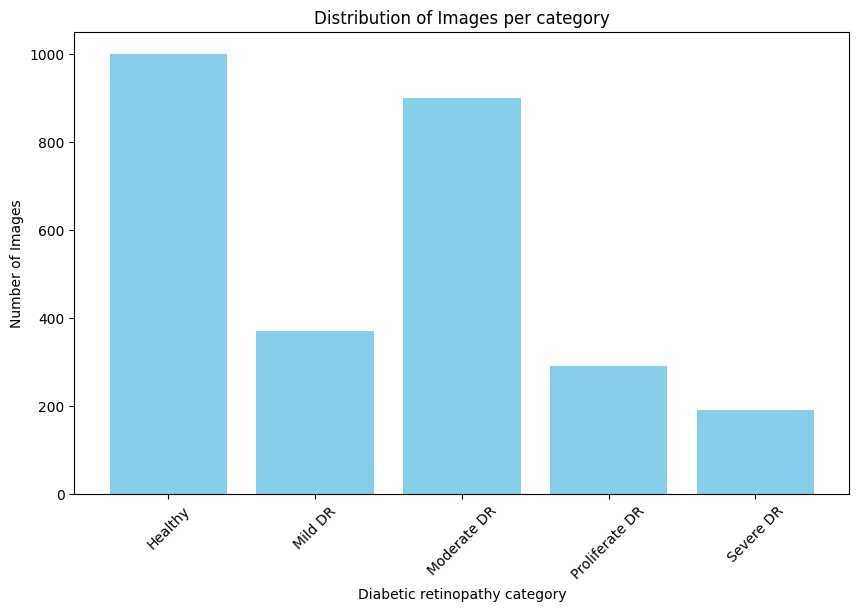

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.bar(counts.keys(), counts.values(), color='skyblue')
plt.xlabel('Diabetic retinopathy category')
plt.ylabel('Number of Images')
plt.title('Distribution of Images per category')
plt.xticks(rotation = 45)
plt.show()

In [5]:
from PIL import Image ,ImageOps

In [3]:
num_cats = len(categories)

plt.figure(figsize=(20, 10)) 

for i, cat in enumerate(categories):
    
    cat_path = os.path.join(data_dir, cat)
    img_name = os.listdir(cat_path)[0] 
    img_path = os.path.join(cat_path, img_name)
    
    img = Image.open(img_path)
    
    
    plt.subplot(1, num_cats, i + 1)
    plt.imshow(img)
    
    plt.title(f"Class: {cat}\nSize: {img.size}", fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

NameError: name 'Image' is not defined

<Figure size 2000x1000 with 0 Axes>

## Image Preprocessing: Scaling & aspect Ratio Preservation -> resize the data in 224x224 pixels 

In this stage, we implement a specialized resizing function to prepare our image for the deep learning models. While the original images are **256x256**, we downsample them to **224x224** to ensure full compatibility with the **MobileNetV2** architecture and its pre-trained ImageNet weights. 

### The strategy: Smart Resizing with Padding 
Unlike standards "stretch-to-fit" resize, which can distort the circular geometry of the fundus, we utilize the 'ImageOps.pad` method:
* **Aspect ratio Maintenance:** The image is scaled proportionally to fit within the target dimensions.
* **Letterboxing (Padding):** If the original aspect ratio differs even slightly, black pixels (`color=(0,0,0)`) are added to fill the gaps.
* **LANCZOS Resampling:** We use high-quality interpolation to preserve as much textural detail as possible (critical for detecting microaneurysms).

### Visual Validation: 
By plotting the **Original vs Resized** version,we confirm that the diagnostic features remain sharp and the anatomical structure of the eye is not warped during the transformation.

> **Technical Requirement:** All images are converted to **RGB** format to ensure a consistent three-channel input for the convolutional layers, regardless of the original file's color profile.

In [7]:
IMG_SIZE = 224

def resize(image_path, target_size=(224,224)):
    img = Image.open(image_path).convert("RGB")
    
    img_resized = ImageOps.pad(
        img,
        target_size,
        method=Image.Resampling.LANCZOS,
        color=(0,0,0)
    )
    
    return img_resized

In [4]:
sample_class = categories[0]
sample_class_path = os.path.join(data_dir, sample_class)

sample_image_name = [
    img for img in os.listdir(sample_class_path)
][0]

sample_path = os.path.join(sample_class_path, sample_image_name)

original_img = Image.open(sample_path).convert("RGB")
resized_img = resize(sample_path, target_size=(IMG_SIZE, IMG_SIZE))

print("Original size:", original_img.size)
print("Resized size:", resized_img.size)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_img)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_img)
plt.title("Resized 224x224")
plt.axis("off")

plt.show()

NameError: name 'Image' is not defined

## Data Augmentation

To reduce overfitting and improve the model's ability to generalize, data augmentation was applied to the training images.

Data augmentation creates slightly modified versions of the original images during training, without changing their class labels. This is especially useful when the dataset is limited or when some classes contain fewer images than others.

In this project, the following augmentation techniques were considered:

* **Rotation:** The image is slightly rotated. This helps the model recognize the same eye condition even when the image orientation changes.

* **Zoom:** The image is slightly zoomed in or out, helping the model focus on important visual patterns such as lesions or abnormalities.

* **Horizontal Flip:** The image is mirrored horizontally, allowing the model to learn features from both left and right eye orientations.

These transformations help increase the diversity of the training data and make the model more robust.